# 2. Individual signal results

This notebook reads the result files from Notebook 1. The charts show returns only. The tables show risk and style data.

**Terms.** A long-only portfolio has no short stock positions. A long-short portfolio can hold short stock positions. Both portfolios are fully invested. Active return is the portfolio return relative to the benchmark return. All charts use cumulative log returns.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path('dataset')
returns = pd.read_parquet(DATA / 'final_returns.parquet')
returns['date'] = pd.to_datetime(returns['date'])
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False,
                     'axes.spines.right': False})

def log_path(frame, field):
    # Add the log of each daily growth value.
    values = frame.sort_values('date')[field].to_numpy()
    assert np.all(values > -1)
    return np.cumsum(np.log1p(values))

def active_log_path(frame):
    # Compare total growth with benchmark growth on each date.
    frame = frame.sort_values('date')
    return np.cumsum(np.log1p(frame['portfolio_return'].to_numpy())
                     - np.log1p(frame['benchmark_return'].to_numpy()))


## 2.1 Why use inflation beta?

Inflation can reduce expected future real consumption. A stock that loses value when inflation rises can add risk in a bad economic period. In Duarte's study, stocks with more negative inflation sensitivity had higher average returns. Investors can accept lower expected returns on stocks that help protect them in these periods. This is a risk premium explanation. It does not prove that the low-beta stocks are mispriced.

Paper: [Fernando Duarte, *Inflation Risk and the Cross Section of Stock Returns* (2013)](https://www.econstor.eu/bitstream/10419/93630/1/749607815.pdf). Our inflation score is negative inflation beta. A high score means more negative measured inflation sensitivity.

## 2.2 Why use DMD?

DMD describes patterns in a stock's recent prices. Some patterns can move up and down. Other patterns can show a trend. The model uses these patterns to forecast a short price move. A pattern is not proof of an economic cause. The portfolio test measures whether the forecast helped in later data.

## 2.3 Original signal returns

The active charts show returns relative to the benchmark. The total charts show the full portfolio returns and the benchmark. Each portfolio has a total stock weight of one.

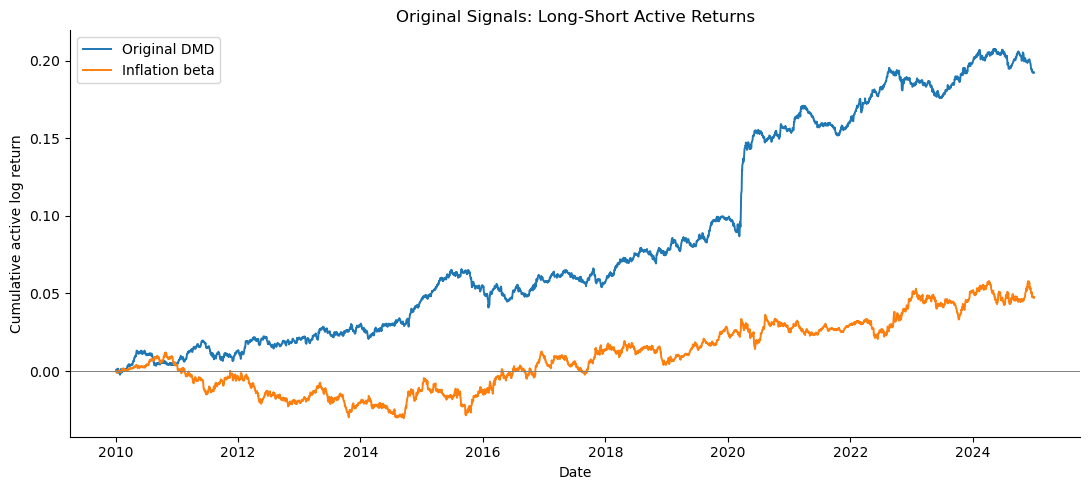

In [2]:
# Show returns for the same set of trade dates.
labels = {'original_dmd_matched_active': 'Original DMD', 'inflation_standalone_active': 'Inflation beta'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if False else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
if False and 'notebook_2' == 'notebook_2':
    benchmark = returns.loc[returns['portfolio'] == next(iter(labels))].sort_values('date')
    ax.plot(benchmark['date'], log_path(benchmark, 'benchmark_return'),
            label='Benchmark', color='black', linewidth=1.1, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Original Signals: Long-Short Active Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if False else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


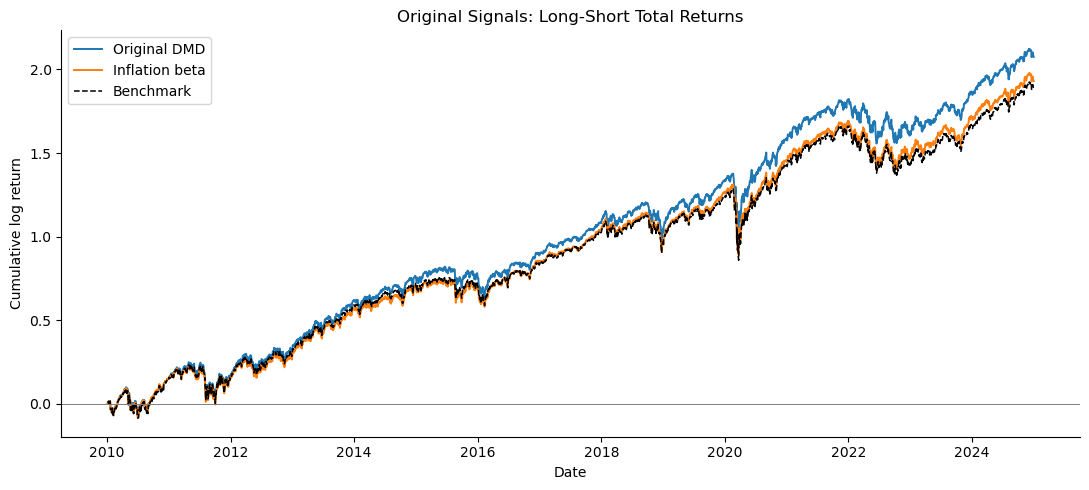

In [3]:
# Show returns for the same set of trade dates.
labels = {'original_dmd_matched_active': 'Original DMD', 'inflation_standalone_active': 'Inflation beta'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if True else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
if True and 'notebook_2' == 'notebook_2':
    benchmark = returns.loc[returns['portfolio'] == next(iter(labels))].sort_values('date')
    ax.plot(benchmark['date'], log_path(benchmark, 'benchmark_return'),
            label='Benchmark', color='black', linewidth=1.1, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Original Signals: Long-Short Total Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if True else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


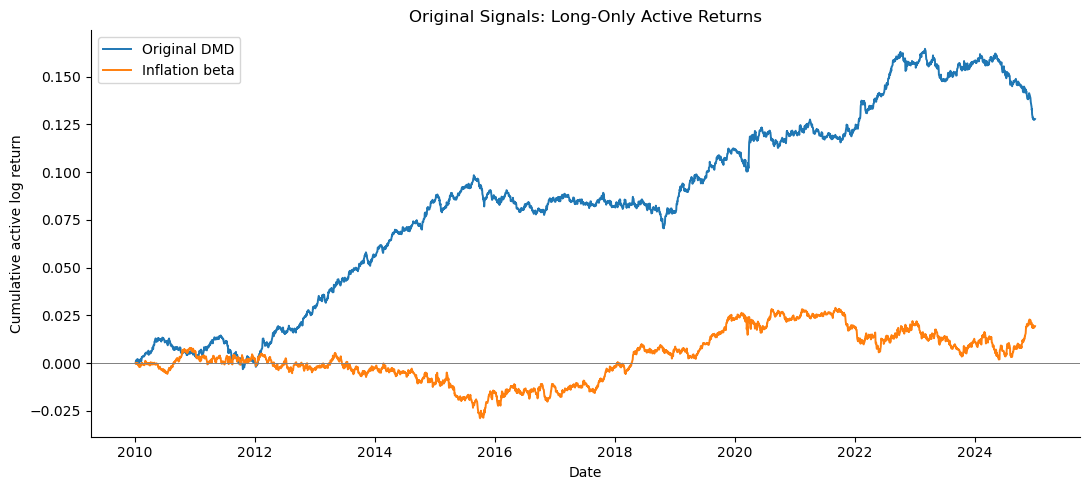

In [4]:
# Show returns for the same set of trade dates.
labels = {'original_dmd_matched_long_only': 'Original DMD', 'inflation_standalone_long_only': 'Inflation beta'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if False else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
if False and 'notebook_2' == 'notebook_2':
    benchmark = returns.loc[returns['portfolio'] == next(iter(labels))].sort_values('date')
    ax.plot(benchmark['date'], log_path(benchmark, 'benchmark_return'),
            label='Benchmark', color='black', linewidth=1.1, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Original Signals: Long-Only Active Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if False else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


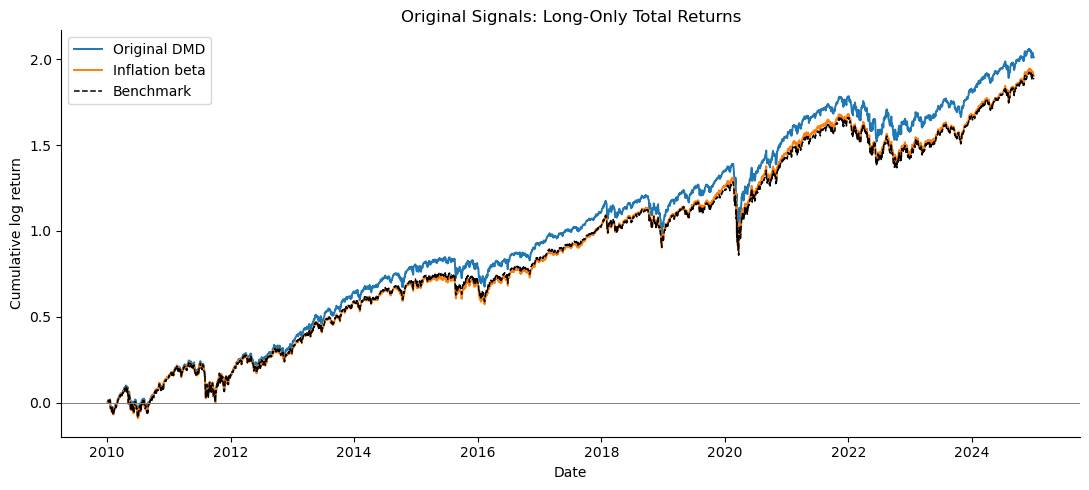

In [5]:
# Show returns for the same set of trade dates.
labels = {'original_dmd_matched_long_only': 'Original DMD', 'inflation_standalone_long_only': 'Inflation beta'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if True else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
if True and 'notebook_2' == 'notebook_2':
    benchmark = returns.loc[returns['portfolio'] == next(iter(labels))].sort_values('date')
    ax.plot(benchmark['date'], log_path(benchmark, 'benchmark_return'),
            label='Benchmark', color='black', linewidth=1.1, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Original Signals: Long-Only Total Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if True else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


## 2.4 Check DMD against momentum and reversal

DMD uses price patterns. Momentum and reversal also use past prices. DMD could repeat these effects. For each date, Notebook 1 fits DMD to Barra momentum and long-term reversal across stocks. It removes the fitted part. The part that remains is the adjusted DMD score. The inflation beta score stays the same. The original and adjusted DMD tests use the same stocks and dates.

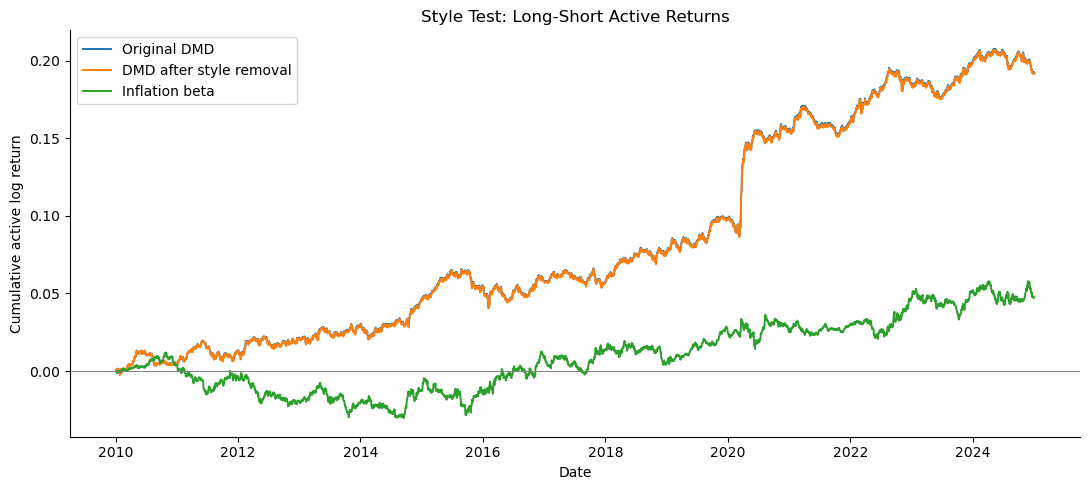

In [6]:
# Show returns for the same set of trade dates.
labels = {'original_dmd_matched_active': 'Original DMD', 'dmd_standalone_active': 'DMD after style removal', 'inflation_standalone_active': 'Inflation beta'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if False else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
if False and 'notebook_2' == 'notebook_2':
    benchmark = returns.loc[returns['portfolio'] == next(iter(labels))].sort_values('date')
    ax.plot(benchmark['date'], log_path(benchmark, 'benchmark_return'),
            label='Benchmark', color='black', linewidth=1.1, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Style Test: Long-Short Active Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if False else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


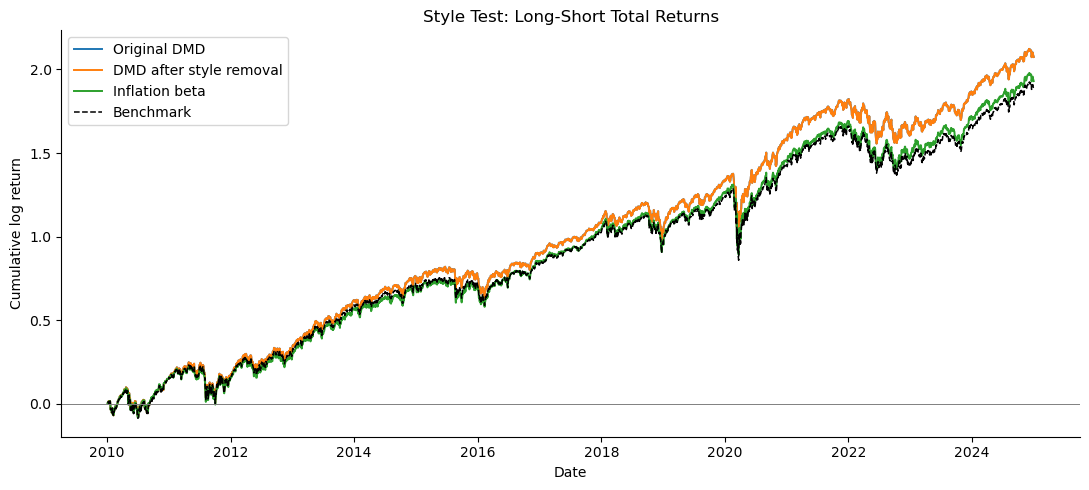

In [7]:
# Show returns for the same set of trade dates.
labels = {'original_dmd_matched_active': 'Original DMD', 'dmd_standalone_active': 'DMD after style removal', 'inflation_standalone_active': 'Inflation beta'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if True else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
if True and 'notebook_2' == 'notebook_2':
    benchmark = returns.loc[returns['portfolio'] == next(iter(labels))].sort_values('date')
    ax.plot(benchmark['date'], log_path(benchmark, 'benchmark_return'),
            label='Benchmark', color='black', linewidth=1.1, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Style Test: Long-Short Total Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if True else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


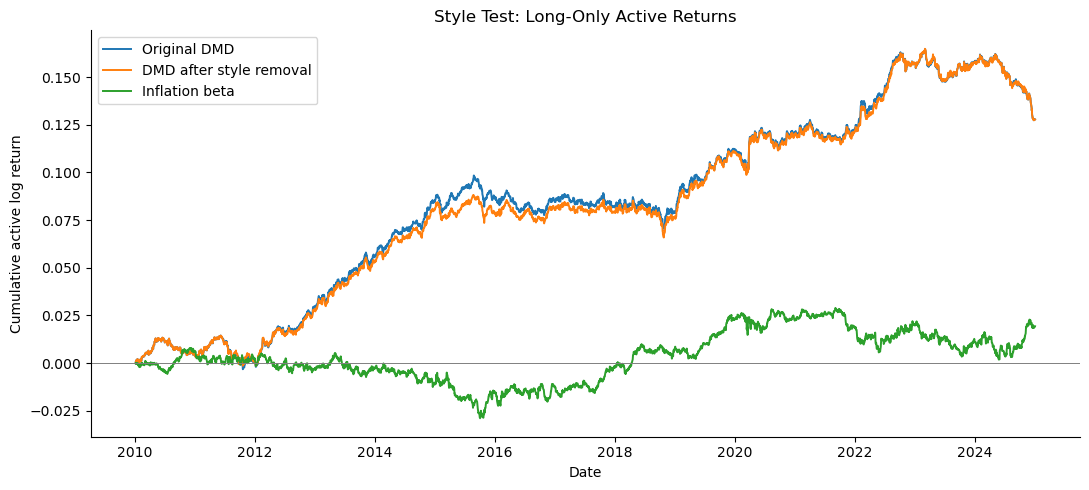

In [8]:
# Show returns for the same set of trade dates.
labels = {'original_dmd_matched_long_only': 'Original DMD', 'dmd_standalone_long_only': 'DMD after style removal', 'inflation_standalone_long_only': 'Inflation beta'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if False else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
if False and 'notebook_2' == 'notebook_2':
    benchmark = returns.loc[returns['portfolio'] == next(iter(labels))].sort_values('date')
    ax.plot(benchmark['date'], log_path(benchmark, 'benchmark_return'),
            label='Benchmark', color='black', linewidth=1.1, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Style Test: Long-Only Active Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if False else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


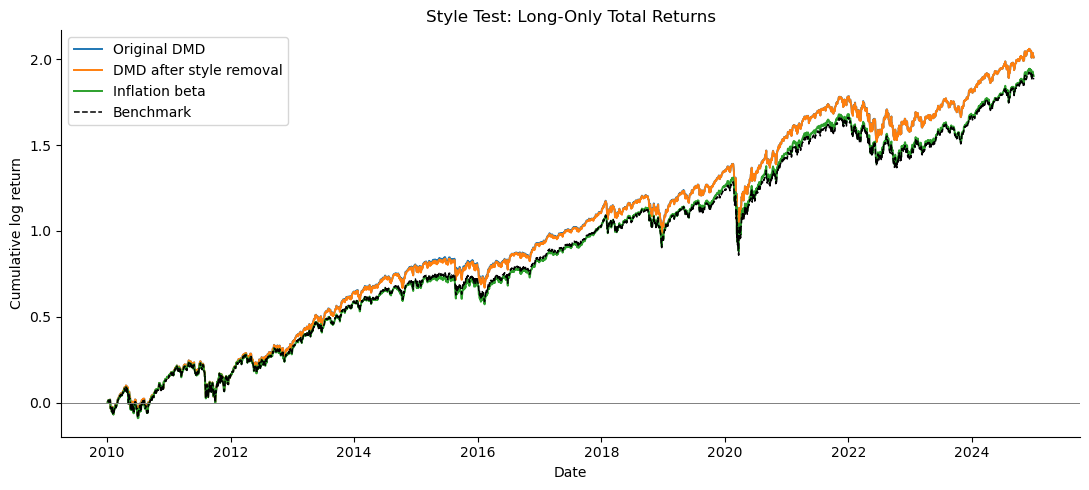

In [9]:
# Show returns for the same set of trade dates.
labels = {'original_dmd_matched_long_only': 'Original DMD', 'dmd_standalone_long_only': 'DMD after style removal', 'inflation_standalone_long_only': 'Inflation beta'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if True else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
if True and 'notebook_2' == 'notebook_2':
    benchmark = returns.loc[returns['portfolio'] == next(iter(labels))].sort_values('date')
    ax.plot(benchmark['date'], log_path(benchmark, 'benchmark_return'),
            label='Benchmark', color='black', linewidth=1.1, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Style Test: Long-Only Total Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if True else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


## 2.5 Style and risk tables

The first table shows the part of the DMD score that Barra momentum and reversal explain. A larger value means more score overlap. This is a score test. It does not measure the share of DMD return that those styles cause. The second table shows average active style exposure. It also shows the largest forecast tracking error and the largest absolute active beta. The tracking-error limit is 1% per year.

In [10]:
style = pd.read_parquet(DATA / 'style_diagnostics.parquet')
style_table = pd.DataFrame({
    'Measure': ['Mean stock coverage', 'Mean share of DMD score explained',
                'Median share of DMD score explained'],
    'Value': [style['coverage'].mean(), style['r2'].mean(), style['r2'].median()]})
display(style_table.style.format({'Value':'{:.2%}'}))

signal_names = {
    'original_dmd_matched_active':'Original DMD: long-short',
    'dmd_standalone_active':'Adjusted DMD: long-short',
    'inflation_standalone_active':'Inflation beta: long-short',
    'original_dmd_matched_long_only':'Original DMD: long-only',
    'dmd_standalone_long_only':'Adjusted DMD: long-only',
    'inflation_standalone_long_only':'Inflation beta: long-only'}
rows = []
for key, label in signal_names.items():
    group = returns.loc[returns['portfolio'] == key]
    rows.append({'Portfolio':label,
                 'Mean momentum exposure':group['lagged_momentum_exposure'].mean(),
                 'Mean reversal exposure':group['lagged_reversal_exposure'].mean(),
                 'Highest forecast tracking error':group['predicted_te'].max(),
                 'Largest absolute active beta':group['active_beta'].abs().max()})
display(pd.DataFrame(rows).set_index('Portfolio').style.format('{:.4f}'))

# Compare the active return before and after style removal.
wide = returns.pivot(index='date', columns='portfolio', values='active_return')
comparison = []
for kind, old, new in [
    ('Long-short active portfolio', 'original_dmd_matched_active', 'dmd_standalone_active'),
    ('Long-only active portfolio', 'original_dmd_matched_long_only', 'dmd_standalone_long_only')]:
    pair = wide[[old, new]].dropna()
    comparison.append({
        'Portfolio': kind,
        'Correlation of active returns': pair[old].corr(pair[new]),
        'Annual active return difference': 252 * (pair[old] - pair[new]).mean()})
display(pd.DataFrame(comparison).set_index('Portfolio').style.format({
    'Correlation of active returns':'{:.4f}',
    'Annual active return difference':'{:.3%}'}))


,Measure,Value
0,Mean stock coverage,99.96%
1,Mean share of DMD score explained,0.29%
2,Median share of DMD score explained,0.18%


,Mean momentum exposure,Mean reversal exposure,Highest forecast tracking error,Largest absolute active beta
Portfolio,,,,
Original DMD: long-short,-0.0001,-0.0008,0.0100,0.0000
Adjusted DMD: long-short,0.0007,0.0001,0.0100,0.0000
Inflation beta: long-short,0.0024,0.0061,0.0100,0.0000
Original DMD: long-only,-0.0034,-0.0184,0.0100,0.0000
Adjusted DMD: long-only,-0.0002,0.0015,0.0100,0.0000
Inflation beta: long-only,0.0079,-0.0113,0.0100,0.0000


,Correlation of active returns,Annual active return difference
Portfolio,,
Long-short active portfolio,1.0000,0.004%
Long-only active portfolio,0.9766,0.002%


## 2.6 Return and volatility table

The table shows both total and active values. Each long-only row has **long-only total portfolio** values and **long-only active portfolio** values. Total volatility includes market moves because each portfolio is fully invested. Active volatility measures the return difference from the benchmark. The information ratio uses annual active return divided by annual active volatility. The test does not subtract trade costs.

In [11]:
summary = []
for key, label in signal_names.items():
    group = returns.loc[returns['portfolio'] == key].sort_values('date')
    total = group['portfolio_return']
    active = total - group['benchmark_return']
    summary.append({'Portfolio': label,
                    'Annual total return': 252 * total.mean(),
                    'Annual total volatility': np.sqrt(252) * total.std(ddof=1),
                    'Annual active return': 252 * active.mean(),
                    'Annual active volatility': np.sqrt(252) * active.std(ddof=1),
                    'Active information ratio': np.sqrt(252) * active.mean() / active.std(ddof=1)})
display(pd.DataFrame(summary).set_index('Portfolio').style.format({
    'Annual total return':'{:.2%}', 'Annual total volatility':'{:.2%}',
    'Annual active return':'{:.2%}', 'Annual active volatility':'{:.2%}',
    'Active information ratio':'{:.2f}'}))


,Annual total return,Annual total volatility,Annual active return,Annual active volatility,Active information ratio
Portfolio,,,,,
Original DMD: long-short,15.47%,17.89%,1.32%,1.32%,1.00
Adjusted DMD: long-short,15.46%,17.88%,1.32%,1.32%,1.00
Inflation beta: long-short,14.50%,17.85%,0.35%,1.37%,0.25
Original DMD: long-only,15.03%,17.85%,0.88%,1.20%,0.74
Adjusted DMD: long-only,15.03%,17.85%,0.88%,1.20%,0.74
Inflation beta: long-only,14.30%,17.78%,0.15%,1.15%,0.13
